# 02 - Different Plot Types
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data*

In [01_matplotlib_basics](01_matplotlib_basics.ipynb) everything was a line plot. In this lesson we learn other plot types - and when to use which one:

| plot type | what it's for | finance example |
|---|---|---|
| bar graph | comparing categories | revenue per business unit, returns per asset class |
| error bars / shading | showing uncertainty | a forecast with a confidence band, mean return ± standard deviation |
| pie chart | parts of a whole | portfolio allocation - 60% stocks, 30% bonds, 10% cash |
| histogram | how values are distributed | daily returns - how often a ±2% day happens |

Every chart is saved to `charts/` and collected in this folder's [README](README.md).

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'

## 1. Simple Bar Chart
**Task:** the cafe MatplotSip sold six drinks last month - plot the sales as bars, with x-values `0, 1, ... n-1`.

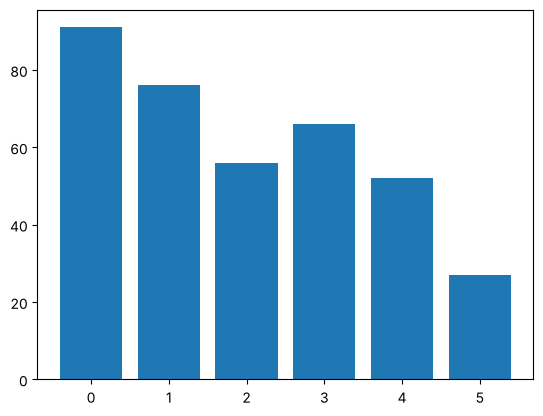

In [2]:
drinks = ["cappuccino", "latte", "chai", "americano", "mocha", "espresso"]
sales =  [91, 76, 56, 66, 52, 27]

plt.figure()
plt.bar(range(len(drinks)), sales)
plt.savefig(CHARTS + '02_01_simple_bar.png')
plt.show()

`plt.bar()` works like `plt.plot()`: x first, then y. The x-values are only **slots** for the categories:

```text
plt.bar(range(len(sales)), sales)
        \_______________/  \___/
         x: 0, 1, 2 ...     y: bar heights
         one slot per drink
```

We can't tell which bar is which drink yet - that's the next step.

**Finance tip:** a bar chart's y-axis should **always start at 0**. A bar's height *is* its value, so a cut-off axis makes small differences look huge (the truncated-axis warning from section 5 of the basics - even stricter for bars). Matplotlib starts bars at 0 by default.

## 2. Simple Bar Chart II - labels
**Task:** create the axes object `ax`, set the x-ticks to `0 ... len(drinks)`, and use the `drinks` list as tick labels.

range(0, 6)
[0, 1, 2, 3, 4, 5]


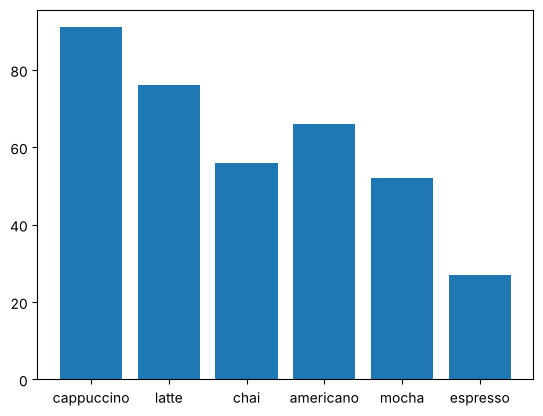

In [3]:
x = range(len(drinks))
print(x)          # what is this?
print(list(x))

plt.figure()
ax = plt.subplot()
plt.bar(x, sales)
ax.set_xticks(x)
ax.set_xticklabels(drinks)
plt.savefig(CHARTS + '02_02_bar_labels.png')
plt.show()

**Learning point:** `print(range(...))` shows `range(0, 6)`, not the numbers. `range` doesn't store the numbers - it's a recipe that hands them out one at a time when something asks. Matplotlib asks, so `set_xticks(range(...))` works; to *see* them, wrap it in `list()`. (In R, `0:5` gives the numbers directly - that's why this one is surprising.)

- Define `x` once and reuse it - no need to type `range(len(drinks))` three times.
- **Ticks before labels:** without explicit ticks, matplotlib might not put one tick under every bar, and the labels end up on the wrong bars.
- Long labels? `ax.set_xticklabels(drinks, rotation=30)` tilts them - useful for tickers or fund names.

## 3. Side-By-Side Bars
**Task:** MatplotSip opened a second location - plot the sales of both stores next to each other, using the x-value template below for each store.

store1_x: [0.8, 2.8, 4.8, 6.8, 8.8, 10.8]
store2_x: [1.6, 3.6, 5.6, 7.6, 9.6, 11.6]


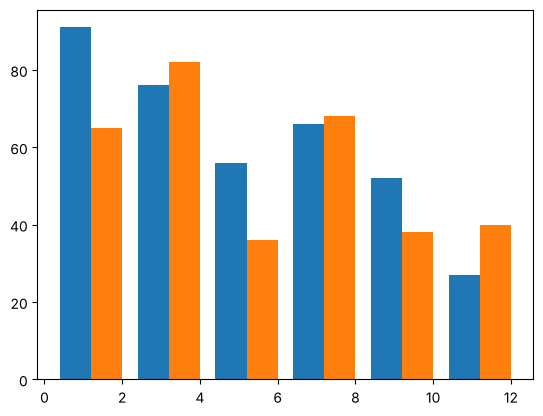

In [4]:
sales1 = [91, 76, 56, 66, 52, 27]
sales2 = [65, 82, 36, 68, 38, 40]

n = 1    # This is our first dataset (out of 2)
t = 2    # Number of datasets
d = 6    # Number of sets of bars
w = 0.8  # Width of each bar
store1_x = [t*element + w*n for element
             in range(d)]

n = 2    # This is our second dataset (out of 2)
t = 2    # Number of datasets
d = 6    # Number of sets of bars
w = 0.8  # Width of each bar
store2_x = [t*element + w*n for element
             in range(d)]

print('store1_x:', store1_x)
print('store2_x:', store2_x)

plt.figure()
plt.bar(store1_x, sales1)
plt.bar(store2_x, sales2)
plt.savefig(CHARTS + '02_03_side_by_side.png')
plt.show()

### The copy-paste template

```python
n = 1    # which dataset is this?      1st -> 1, 2nd -> 2, 3rd -> 3 ...
t = 2    # how many datasets in total  (bars per group)
d = 6    # how many groups             = len(categories), here len(drinks)
w = 0.8  # width of one bar            0.8 is matplotlib's default
store1_x = [t*element + w*n for element in range(d)]
```

**How to fill it in - 4 questions:**

| variable | ask yourself | MatplotSip |
|---|---|---|
| `n` | which dataset am I placing *right now*? | store 1 -> `1`, store 2 -> `2` |
| `t` | how many datasets sit next to each other? | 2 stores -> `2` |
| `d` | how many groups (categories) are on the x-axis? | 6 drinks -> `6` |
| `w` | how wide is one bar? | keep `0.8` |

**Rule:** paste the block once per dataset. Only `n` changes - `t`, `d`, `w` stay the same. Rename the result each time (`store1_x`, `store2_x`). Three datasets? Same block three times with `t = 3` and `n = 1, 2, 3`.

### What it does: it only picks the positions
The list only calculates **where** each bar stands on the x-axis. It doesn't draw anything and has nothing to do with the sales numbers:

```text
plt.bar(  store1_x,   sales1 )
          \______/    \____/
          where the   how tall
          bars stand  they are
```

It makes sure each comparison pair stands next to each other, **touching**, with a small **gap** before the next pair:

```text
 0.8  1.6        2.8  3.6        4.8  5.6
 [S1][S2]  gap   [S1][S2]  gap   [S1][S2]   ...
 cappuccino       latte            chai

touching: store 2 starts exactly 1 bar width (w = 0.8) after store 1
gap:      each group gets t = 2 units of space, the pair fills only 2 x 0.8 = 1.6
          -> 0.4 left empty before the next pair
```

### How the line works: `[t*element + w*n for element in range(d)]`

**Read it as a sentence, from the middle outwards:**
```text
[ t*element + w*n    for element in range(d) ]
  \_____________/    \____________________/
   2) calculate       1) for every number
      this ...           0, 1, 2, 3, 4, 5
```
"**For every** `element` in 0-5, **calculate** `t*element + w*n`, and **collect the results in a list**." The square brackets are the list being filled; `element` is just a name for "the number we're on right now".

**The formula:**
```text
t*element  +  w*n
\_______/     \_/
 jump to       move into this dataset's slot inside the group
 the group     (n=1: 1 bar width in, n=2: 2 bar widths in)
 (t units per group = room for t bars)
```

**The same thing as a normal loop** - what Python does behind the scenes:
```python
store1_x = []                      # start with an empty list
for element in range(d):           # element = 0, then 1, then 2 ... 5
    x = t*element + w*n            # calculate one position
    store1_x.append(x)             # add it to the list
```

**By hand** (t = 2, w = 0.8, n = 1):
```text
element = 0  ->  2*0 + 0.8*1  =  0.8    store1_x = [0.8]
element = 1  ->  2*1 + 0.8*1  =  2.8    store1_x = [0.8, 2.8]
element = 2  ->  2*2 + 0.8*1  =  4.8    store1_x = [0.8, 2.8, 4.8]
...
element = 5  ->  2*5 + 0.8*1  = 10.8    store1_x = [0.8, 2.8, 4.8, 6.8, 8.8, 10.8]
```

**In R** there's no loop needed - R calculates on whole vectors: `store1_x <- 2 * (0:5) + 0.8 * 1`. Plain Python lists can't (`2 * [0, 1, 2]` *repeats* the list), so the list comprehension is Python's way of saying "apply this to every element". NumPy can do it the R way: `t * np.arange(d) + w * n`.

**Don't** change `t` or `d` between the blocks - if store 2 used `t = 3`, its bars would spread out at a different rhythm and no longer line up with store 1.

## 4. Stacked Bars
**Task:** stack the two stores instead of placing them side by side - `sales1` on the bottom, `sales2` starting where `sales1` ends - and add a legend "Location 1" / "Location 2".

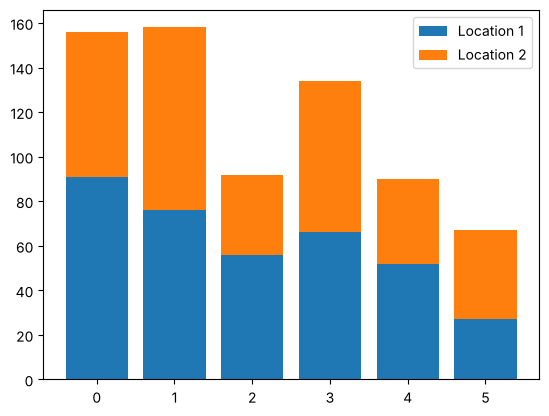

In [5]:
plt.figure()
plt.bar(range(len(sales1)),
  sales1)

plt.bar(range(len(sales2)),
  sales2,
  bottom = sales1)

plt.legend(["Location 1","Location 2"])
plt.savefig(CHARTS + '02_04_stacked_bars.png')
plt.show()

**Learning point - which one is the bottom?** `bottom=` doesn't mean "this is the bottom dataset". It is the height where *this* bar starts - its floor.

```text
plt.bar(x, sales2, bottom=sales1)
           \____/  \___________/
           this     start it where
           bar's    sales1 ENDS
           height

cappuccino:
   156 +------+  <- 91 + 65
       | S2=65|  sales2 sits ON TOP
    91 +------+
       | S1=91|  sales1 drawn normally, from 0
     0 +------+
```

**Rule:** the dataset you put in `bottom=` is the one **underneath**. The bars you are drawing go second, the bars they sit on go in `bottom=`.

- The legend labels are matched to the bars in the order they were plotted.
- Side-by-side bars compare the stores better; stacked bars show the **total** better. Finance: revenue per quarter split by business unit, or a portfolio split into stocks and bonds per year.
- **Three layers?** The third floor is the first two combined: `bottom=[a + b for a, b in zip(sales1, sales2)]` (with NumPy arrays simply `sales1 + sales2`).

## 5. Error Bars
**Task:** plot the ounces of milk in each drink as bars, show the ±10% `error` as error bars, with caps of size 5.

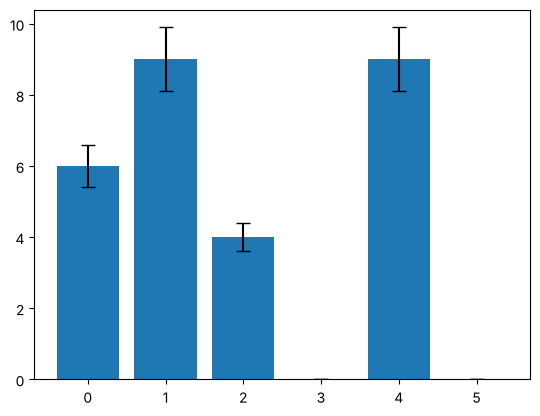

In [6]:
ounces_of_milk = [6, 9, 4, 0, 9, 0]
error = [0.6, 0.9, 0.4, 0, 0.9, 0]

plt.figure()
plt.bar(range(len(drinks)),ounces_of_milk, yerr=error, capsize=5)
plt.savefig(CHARTS + '02_05_error_bars.png')
plt.show()

```text
plt.bar(x, ounces_of_milk, yerr=error, capsize=5)

latte: value 9, error 0.9
   9.9  -+-   <- cap (capsize = how wide this line is)
         |
   9.0 +-|-+  <- the bar's real height
       | | |     the error bar runs from 9 - 0.9 to 9 + 0.9
   8.1 |-+-|  <- cap
       |   |
     0 +---+
```

- `yerr=2` - the **same** error on every bar (±2).
- `yerr=[...]` - **one error per bar**, matched by position like the tick labels.
- Americano and espresso have no error bar: 0 oz of milk -> error 0 -> nothing to draw.
- `error` is 10% of each value, so it can be calculated instead of typed: `error = [m * 0.1 for m in ounces_of_milk]`.

**Finance:** average return ± standard deviation per asset class. Two equal bars with very different error bars = the same average return, but very different risk.

## 6. Fill Between
**Task:** plot MatplotSip's projected monthly revenue with month names as x-tick labels, then shade a ±10% band around it with `fill_between` (`alpha=0.2`).

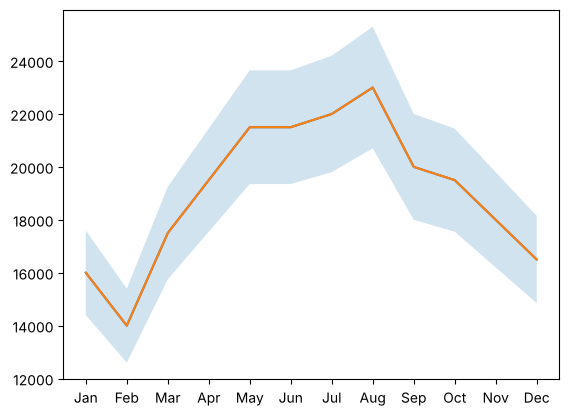

In [7]:
months = range(12)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
revenue = [16000, 14000, 17500, 19500, 21500, 21500, 22000, 23000, 20000, 19500, 18000, 16500]

plt.figure()
plt.plot(months, revenue)

ax = plt.subplot()
ax.set_xticks(months)
ax.set_xticklabels(month_names)

y_lower = [0.9 * i for i in revenue]
y_upper = [1.1 * i for i in revenue]
plt.fill_between(months, y_lower, y_upper, alpha = 0.2)
plt.plot(months, revenue)
plt.savefig(CHARTS + '02_06b_mistake_line_drawn_twice.png')
plt.show()

**Mistake: the line is drawn twice.** `plt.plot(months, revenue)` runs at the top *and* at the bottom. They sit exactly on top of each other, so it looks like one line - but every new line gets the next colour: the first line is blue, the second one orange, and the orange line hides the blue one. (That's why the line in this chart is orange and the band blue - in the fixed version below both are blue.)

**Pattern: band first, line on top - and only once:**

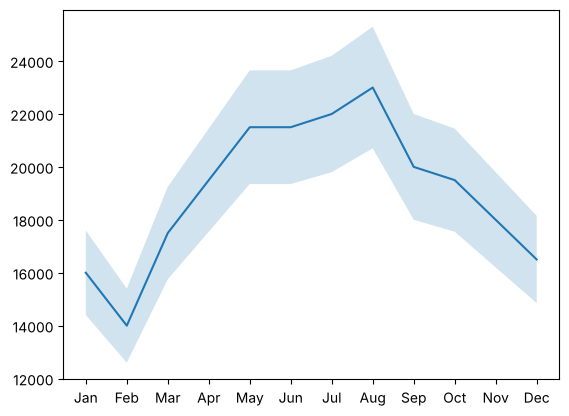

In [8]:
plt.figure()
ax = plt.subplot()
ax.set_xticks(months)
ax.set_xticklabels(month_names)

y_lower = [0.9 * i for i in revenue]
y_upper = [1.1 * i for i in revenue]

plt.fill_between(months, y_lower, y_upper, alpha=0.2)  # shaded band, drawn first
plt.plot(months, revenue)                              # the line on top
plt.savefig(CHARTS + '02_06_fill_between.png')
plt.show()

```text
plt.fill_between(months, y_lower, y_upper, alpha=0.2)
                 \____/  \_____/  \_____/  \_______/
                 x like   floor of  top of    0 = invisible
                 plot()   the band  the band  1 = solid
```

**List comprehension again:** `[0.9 * i for i in revenue]` = "for every `i` in revenue, calculate `0.9 * i`, collect the results in a list".

- In R this is just `revenue * 0.9` - R calculates on whole vectors.
- On a plain Python list, `revenue * 0.9` is a `TypeError`, and `revenue - 2` too (`unsupported operand type(s) for -: 'list' and 'int'`).
- NumPy arrays and pandas columns behave like R: `df['revenue'] * 0.9` works. That's why real finance data lives in pandas.

- Style: `alpha=0.2` - no spaces around `=` inside a function call (works either way, but it's the convention).
- Same colour for band and line: `color='steelblue'` in both calls.

**Finance:** a forecast with a confidence band, or a fund's NAV with a min/max range. A shaded band is easier to read on a line than error bars.

## 7. Pie Chart
**Task:** show how many MatplotSip customers pay by card, cash, Apple Pay or other as a pie chart, then set the axes to be equal.

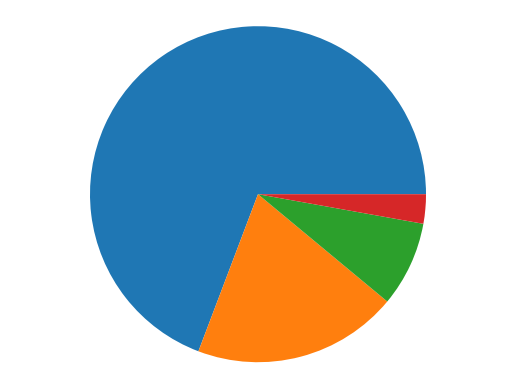

In [9]:
payment_method_names = ["Card Swipe", "Cash", "Apple Pay", "Other"]
payment_method_freqs = [270, 77, 32, 11]

plt.figure()
plt.pie(payment_method_freqs)
plt.axis('equal')
plt.savefig(CHARTS + '02_07_pie.png')
plt.show()

- `plt.pie(values)` - each value becomes its share of the total. You pass the **totals**, not raw rows (from a DataFrame: `df['col'].value_counts()` first).
- `plt.axis('equal')` - x and y get the same scale, so the pie is a circle, not an oval. Newer Matplotlib draws pies round anyway; keeping the line costs nothing.
- No idea yet which slice is which - `payment_method_names` isn't used. That's the next exercise.

**When a pie makes sense:** only when the parts add up to a meaningful whole - portfolio weights, revenue by product, payment methods. For comparing values over time, use a line or bar chart.

## 8. Pie Chart Labeling
**Task:** add a legend with `payment_method_names`, and a percentage on each slice with `autopct`, one decimal place.

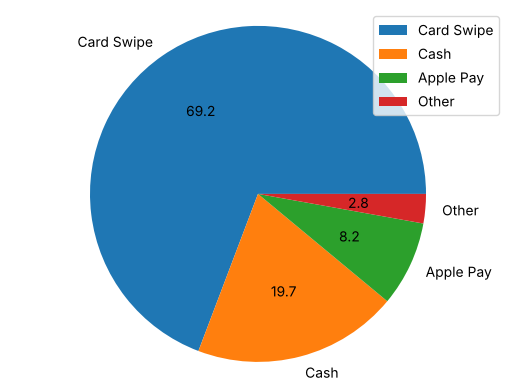

In [10]:
plt.figure()
plt.pie(payment_method_freqs,
  autopct = '%0.1f',
  labels = payment_method_names)
plt.axis('equal')

plt.legend(payment_method_names)
plt.savefig(CHARTS + '02_08b_mistake_double_labels.png')
plt.show()

**Two mistakes:**
1. **No percent sign.** `'%0.1f'` prints `69.2`, not `69.2%` - a reader can't tell it's a share. It needs `'%0.1f%%'`.
2. **Every name appears twice** - once from `labels=` on the slices and once in the legend. Pick one:
   - legend - cleaner when names are long or slices are tiny (here "Other" is 2.8%)
   - `labels=` - easier to read, the eye doesn't jump between pie and legend

**Fixed, legend style:**

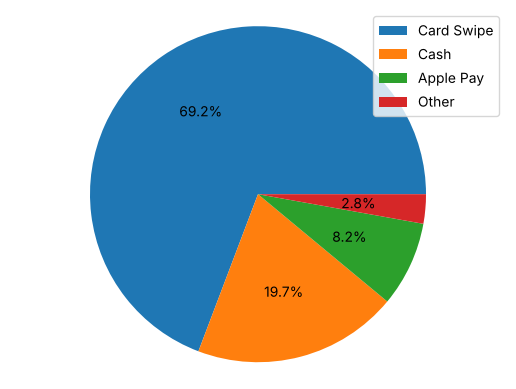

In [11]:
plt.figure()
plt.pie(payment_method_freqs, autopct='%0.1f%%')
plt.axis('equal')
plt.legend(payment_method_names)
plt.savefig(CHARTS + '02_08_pie_labels.png')
plt.show()

**`autopct` format strings** - the same codes as R's `sprintf()`:

```text
'%0.1f%%'
 \____/\/
   |    +-- %% = a real % sign (one % alone starts a format code)
   +------- one decimal place

'%0.2f'    ->  4.08
'%0.2f%%'  ->  4.08%
'%d%%'     ->  4%
```

R: `sprintf("%.1f%%", 69.23)` gives `"69.2%"` - identical syntax.

**Rounding:** the four slices show 69.2 + 19.7 + 8.2 + 2.8 = **99.9%**. Rounded percentages often don't add up to exactly 100 - good to know before someone asks about it in a report.

## 9. Histogram
**Task:** make a histogram of the times of MatplotSip's 270 sales in one day, first with the default bins, then with `bins=20`:

```python
plt.hist(sales_times)
plt.hist(sales_times, bins=20)
```

The Codecademy file `sales_times.csv` has a column of card numbers, so it isn't kept in this public repo. The examples below use the made-up practice data in [`data/cafe_transactions.csv`](../../data/cafe_transactions.csv) - 320 sales at a Vienna cafe in September 2026.

   time      hour
0  7:23  7.383333
1  8:09  8.150000
2  8:33  8.550000


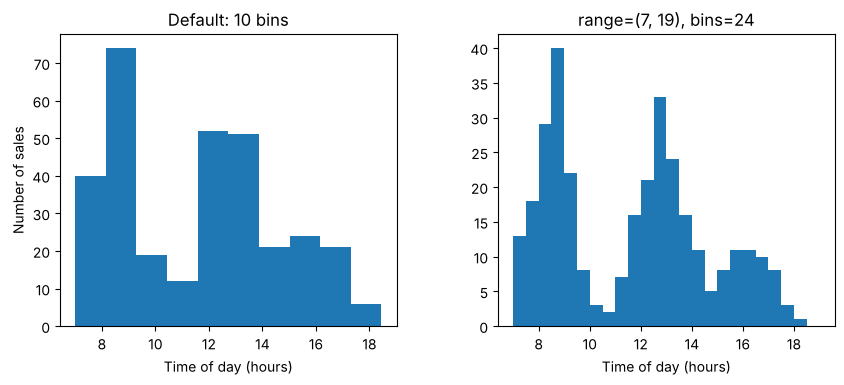

In [12]:
import pandas as pd

sales = pd.read_csv('../../data/cafe_transactions.csv')

# "8:47" -> 8.78  (hours + minutes / 60) - Codecademy's script.py did this step for us
t = pd.to_datetime(sales['time'], format='%H:%M')
sales['hour'] = t.dt.hour + t.dt.minute / 60
print(sales[['time', 'hour']].head(3))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(sales['hour'])                            # default: 10 bins
plt.title('Default: 10 bins')
plt.xlabel('Time of day (hours)')
plt.ylabel('Number of sales')

plt.subplot(1, 2, 2)
plt.hist(sales['hour'], range=(7, 19), bins=24)    # 24 bins over 12 hours = 30 minutes each
plt.title('range=(7, 19), bins=24')
plt.xlabel('Time of day (hours)')

plt.subplots_adjust(wspace=0.3, bottom=0.15)
plt.savefig(CHARTS + '02_09_histogram.png')
plt.show()

**Why a histogram?** Bar and pie charts compare named categories. A histogram answers: across all the values, **where do they fall?** It shows the *shape* of the data, which an average hides - the average sale time is early afternoon, which says nothing about the rush hours.

```text
plt.hist(data, range=(7, 19), bins=24)
               \_________/   \_____/
               only values   number of equal-width bins
               from 7 to 19  default 10, between min and max

each bar = one bin; its height = how many values fall inside it

  count
   |        ##
   |       ####          ##
   |      ######  #   ######
   |  #  ######## ## ########  #
   +-------------------------------- hour
     7   8:30    12:45   16:00   19
         morning  lunch   afternoon
```

- **Bins trade-off:** too few bars hide the pattern (with the default 10 bins each bar covers over an hour, and the afternoon bump almost disappears), too many turn it into noise.
- **Time conversion:** `pd.to_datetime(..., format='%H:%M')` uses the same codes as R's `strptime`; `.dt.hour` / `.dt.minute` pull parts out of a datetime column, like `lubridate::hour()`.
- **R:** `hist(x, breaks = 20)` - but R treats `breaks` as a suggestion and picks "nice" cut points; Matplotlib gives exactly 20 equal bins.

**Finance:** a histogram of daily returns is one of the first charts an analyst looks at - are returns centred around 0? Are there fat tails (crash days)? Is it skewed?

## 10. Multiple Histograms
**Task:** plot the sales times of the second location (371 sales) on top of the first (270), make both see-through with `alpha=0.4`, then normalize both with `density=True`.

My Codecademy code (`sales_times1` / `sales_times2` come from the course's `script.py`):

```python
plt.hist(sales_times1, bins=20, alpha=0.4, density = True)
#plot your other histogram here

plt.hist(sales_times2, bins=20, density = True)

plt.show()
```

**Mistake:** the second histogram is missing `alpha=0.4` - the task says *both*. Without it the second one is solid and covers the first.

Same idea with the practice data: do card and cash customers come at different times? There are far more card payments than cash, so the groups have very different sizes.

card sales: 192 | cash sales: 54


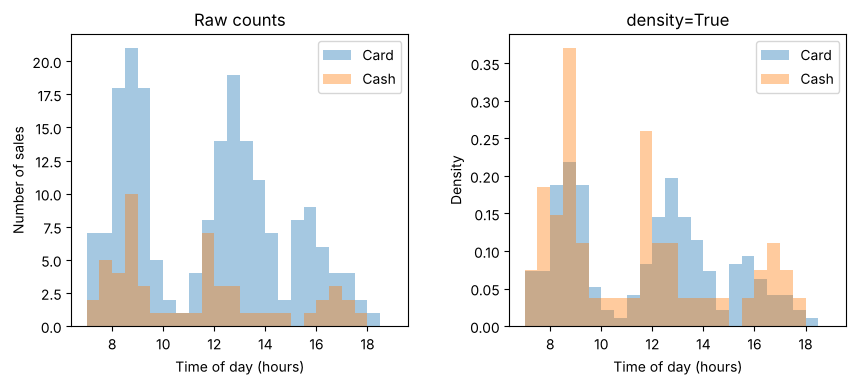

In [13]:
card = sales[sales['payment_method'] == 'Card']['hour']
cash = sales[sales['payment_method'] == 'Cash']['hour']
print('card sales:', len(card), '| cash sales:', len(cash))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(card, range=(7, 19), bins=24, alpha=0.4)
plt.hist(cash, range=(7, 19), bins=24, alpha=0.4)
plt.title('Raw counts')
plt.xlabel('Time of day (hours)')
plt.ylabel('Number of sales')
plt.legend(['Card', 'Cash'])

plt.subplot(1, 2, 2)
plt.hist(card, range=(7, 19), bins=24, alpha=0.4, density=True)
plt.hist(cash, range=(7, 19), bins=24, alpha=0.4, density=True)
plt.title('density=True')
plt.xlabel('Time of day (hours)')
plt.ylabel('Density')
plt.legend(['Card', 'Cash'])

plt.subplots_adjust(wspace=0.3, bottom=0.15)
plt.savefig(CHARTS + '02_10_multiple_histograms.png')
plt.show()

**Why normalize - doesn't it distort the real numbers?** It changes the *question*, not the data:

| | raw counts | `density=True` |
|---|---|---|
| question | how many sales in this slot? | what **share** of this group's sales is in this slot? |
| y-axis | number of sales | density - bar height x bar width = share |
| total | the group's size | area = 1 for every group |
| use when | you need real amounts ("40 more coffees in the evening") | you compare **patterns** between groups of different size |

Left chart: card looks busier all day - only because there are 192 card payments and only 54 cash. Right chart: both groups have the same morning and lunch peaks - card and cash customers come at roughly the same times. The cash bars are spikier because 54 sales is a small sample: a few extra sales in one half hour move its share a lot.

```text
reading a density bar:
bin width = 30 min = 0.5 h,  bar height = 0.20
-> 0.5 x 0.20 = 0.10 = 10% of that group's sales fall in this half hour
```

**Two ways to see through overlapping histograms:**
- `alpha=0.4` - transparent fill
- `histtype='step'` - outline only, no fill

**Same `range=` and `bins=` for both** - otherwise each `plt.hist` picks its own bins from its own min/max, and the bars don't line up. (R: pass the same `breaks` vector to both `hist()` calls.)

**Finance:** comparing the return distribution of a stock with 20 years of history to one listed 3 years ago - you care about the shape (volatility, fat tails), not that one has 7x more days.

## 11. Quiz - questions I got wrong

**1. What is the command to stack a set of bars representing `y2` on top of the bars representing `y1`?**

```python
plt.bar(range(len(y2)), y2, bottom=y1)
```

The bars being drawn (`y2`) go second; the bars they sit on (`y1`) go in `bottom=`. Wrong options: `plt.stack(...)` doesn't exist, and there is no `top=` or `stack=` keyword. See [section 4](#4.-Stacked-Bars).

**2. What are the inputs to `plt.bar`, in order?**

x values (list of numbers), y values (list of numbers) - the same order as `plt.plot(x, y)`. The x-values are slot positions like `range(len(sales))`; the names go on later with `ax.set_xticklabels(...)`. Modern Matplotlib also accepts strings for x (`plt.bar(['Cash', 'Card'], [77, 270])`), but side-by-side bars need numeric positions to shift. See [section 1](#1.-Simple-Bar-Chart).